# Amazon Alexa Reviews — Sentiment Analysis

Can we tell whether a customer is unhappy with their Alexa device from the text of their review alone?

This notebook explores ~3,000 verified Amazon reviews of Echo, Echo Dot, Echo Show, Echo Spot, Echo Plus and Fire TV Stick devices, then trains a text classifier to flag **negative** reviews (1–2 stars).

**Contents**
1. Load and inspect the data
2. Cleaning (blank reviews, duplicates, messy labels)
3. Exploratory analysis
4. Modelling — baselines, model comparison, tuning
5. Evaluation on a held-out test set
6. What the model learned & where it fails
7. Conclusions

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    make_scorer,
    precision_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

DATA_PATH = Path("../data/amazon_alexa_reviews.csv")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

RANDOM_STATE = 42
POS_COLOR, NEG_COLOR = "#2a9d8f", "#e76f51"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

## 1. Load and inspect the data

In [2]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head()

(3150, 5)


,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer a question correctly but Alexa says you got it wrong and answers the ...",1
3,5,31-Jul-18,Charcoal Fabric,"I have had a lot of fun with this thing. My 4 yr old learns about dinosaurs, i control the lights and play games lik...",1
4,5,31-Jul-18,Charcoal Fabric,Music,1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   rating            3150 non-null   int64
 1   date              3150 non-null   str  
 2   variation         3150 non-null   str  
 3   verified_reviews  3149 non-null   str  
 4   feedback          3150 non-null   int64
dtypes: int64(2), str(3)
memory usage: 123.2 KB


Five columns:

| column | description |
|---|---|
| `rating` | star rating, 1–5 |
| `date` | review date (May–July 2018) |
| `variation` | device model / finish |
| `verified_reviews` | review text |
| `feedback` | 1 = positive, 0 = negative |

`feedback` is not an independent label — it is derived directly from the star rating:

In [4]:
pd.crosstab(raw['rating'], raw['feedback'])

feedback,0,1
rating,,
1,161,0
2,96,0
3,0,152
4,0,455
5,0,2286


Ratings of 1–2 map to `feedback = 0` and 3–5 to `feedback = 1`. That means `rating` must **not** be used as a model input (it would leak the answer); the classifier works from review text only.

## 2. Cleaning

In [5]:
df = raw.copy()
df["verified_reviews"] = df["verified_reviews"].fillna("").str.strip()
df["variation"] = df["variation"].str.split().str.join(" ")  # "Black  Dot " -> "Black Dot"
df["date"] = pd.to_datetime(df["date"], format="%d-%b-%y")
df["sentiment"] = df["feedback"].map({1: "positive", 0: "negative"})

blank = df["verified_reviews"].eq("")
print(f"Blank reviews:            {blank.sum()}")
df = df[~blank]

dupes = df["verified_reviews"].duplicated()
print(f"Duplicate review texts:   {dupes.sum()} ({dupes.mean():.0%} of non-blank reviews)")

Blank reviews:            80
Duplicate review texts:   771 (25% of non-blank reviews)


A quarter of the reviews are exact text duplicates. Some are genuinely common short phrases ("Love it!"), but most are the same review listed under several device variations. Left in, they would end up on both sides of a train/test split and inflate the scores (quantified in section 4).

Before dropping them, check that no duplicated text carries conflicting labels:

In [6]:
conflicts = df.groupby("verified_reviews")["feedback"].nunique().gt(1).sum()
print(f"Texts with conflicting labels: {conflicts}")

reviews = df.drop_duplicates("verified_reviews").reset_index(drop=True)
reviews["n_words"] = reviews["verified_reviews"].str.split().str.len()
print(f"Reviews after cleaning: {len(reviews)}")

Texts with conflicting labels: 0
Reviews after cleaning: 2299


## 3. Exploratory analysis

The EDA below uses the deduplicated set, so each distinct review counts once.

### Rating distribution

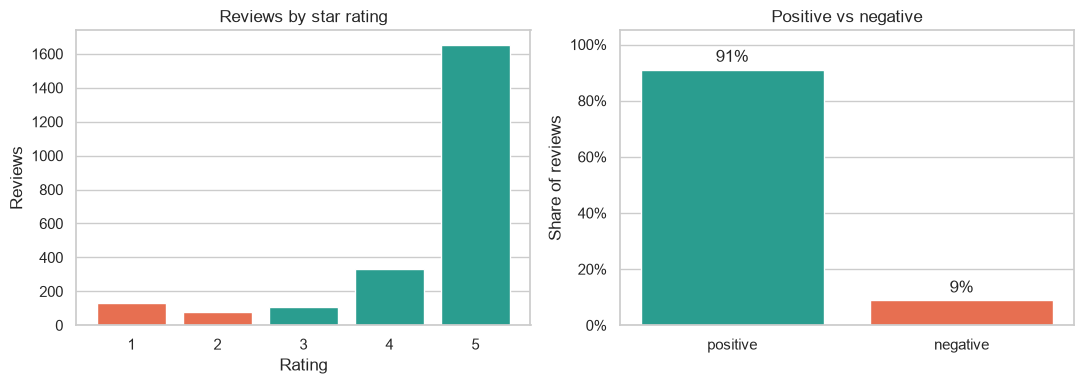

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

rating_counts = reviews["rating"].value_counts().sort_index()
colors = [NEG_COLOR if r <= 2 else POS_COLOR for r in rating_counts.index]
axes[0].bar(rating_counts.index, rating_counts.values, color=colors)
axes[0].set(title="Reviews by star rating", xlabel="Rating", ylabel="Reviews")
axes[0].grid(axis="x", visible=False)

sentiment_share = reviews["sentiment"].value_counts(normalize=True)
axes[1].bar(sentiment_share.index, sentiment_share.values, color=[POS_COLOR, NEG_COLOR])
axes[1].set(title="Positive vs negative", ylabel="Share of reviews", ylim=(0, 1.05))
axes[1].grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for i, v in enumerate(sentiment_share.values):
    axes[1].text(i, v + 0.015, f"{v:.0%}", ha="center", va="bottom")

fig.tight_layout()
fig.savefig(IMAGES / "rating_distribution.png", dpi=150, bbox_inches="tight")

Reviews are overwhelmingly positive. Only **~9%** are negative, so a model that always predicts "positive" would score ~91% accuracy while catching zero unhappy customers. Accuracy is therefore the wrong metric here; the evaluation focuses on **precision, recall and F1 for the negative class**, and on **average precision (PR-AUC)**.

### Ratings by device

In [8]:
by_variation = (
    reviews.groupby("variation")
    .agg(reviews=("rating", "size"), mean_rating=("rating", "mean"), pct_negative=("feedback", lambda s: 1 - s.mean()))
    .sort_values("mean_rating")
)
by_variation.style.format({"mean_rating": "{:.2f}", "pct_negative": "{:.1%}"})

,reviews,mean_rating,pct_negative
variation,,,
White,83,4.18,16.9%
Black,246,4.22,13.8%
White Show,80,4.29,12.5%
Black Spot,226,4.31,13.3%
Sandstone Fabric,43,4.33,7.0%
Black Plus,254,4.36,10.6%
White Plus,74,4.38,9.5%
White Spot,102,4.39,8.8%
White Dot,85,4.45,5.9%


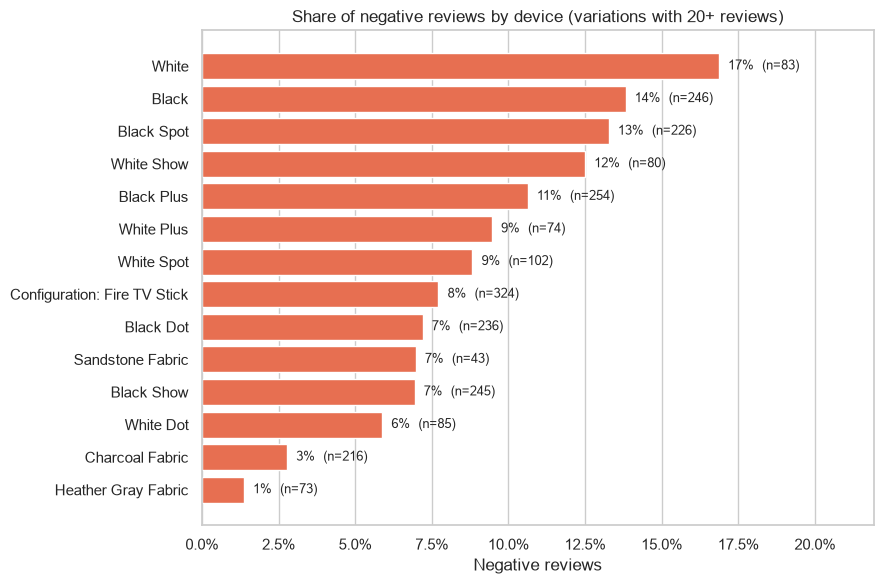

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = by_variation[by_variation["reviews"] >= 20].sort_values("pct_negative")
ax.barh(plot_df.index, plot_df["pct_negative"], color=NEG_COLOR)
ax.set(title="Share of negative reviews by device (variations with 20+ reviews)", xlabel="Negative reviews")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for y, (pct, n) in enumerate(zip(plot_df["pct_negative"], plot_df["reviews"])):
    ax.text(pct + 0.003, y, f"{pct:.0%}  (n={n})", va="center", fontsize=9)
ax.set_xlim(0, plot_df["pct_negative"].max() * 1.3)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(IMAGES / "negative_by_device.png", dpi=150, bbox_inches="tight")

Every device averages above 4 stars, but the share of unhappy customers varies a lot:

- The **fabric-finish Echos** (Charcoal, Heather Gray) have the fewest complaints, at 1–3% negative.
- The plain **Black/White** variations and the **Echo Spot/Show** get the most, at 12–17% negative.
- The **Fire TV Stick** has the largest sample (324 reviews) and sits close to the overall average at 8%.

The per-device sample sizes are small (a 17% rate on 83 reviews is 14 reviews), so these are differences to investigate rather than firm conclusions.

### Review length

In [10]:
reviews.groupby("sentiment")["n_words"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,205.0,44.9,45.4,1.0,15.0,31.0,59.0,307.0
positive,2094.0,26.2,35.6,1.0,7.0,15.0,32.0,526.0


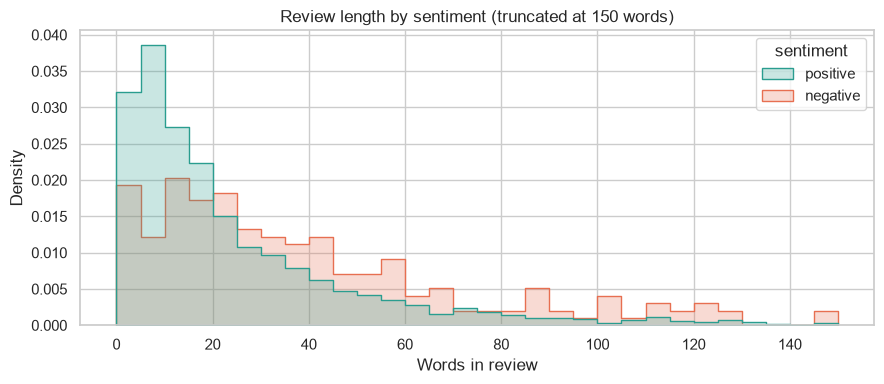

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=reviews, x="n_words", hue="sentiment", stat="density", common_norm=False,
    bins=np.arange(0, 151, 5), palette={"positive": POS_COLOR, "negative": NEG_COLOR}, element="step", ax=ax,
)
ax.set(title="Review length by sentiment (truncated at 150 words)", xlabel="Words in review", ylabel="Density")
fig.tight_layout()
fig.savefig(IMAGES / "review_length.png", dpi=150, bbox_inches="tight")

Unhappy customers write about **twice as much**, with a median of 31 words against 15 for positive reviews. A typical positive review is a short "Love it!", while negative reviews explain what went wrong. The distributions still overlap heavily, so length on its own is a weak signal. The vocabulary carries most of the information.

## 4. Modelling

**Task:** binary classification of review text, with *negative* as the positive class (it's the one we want to catch).

The data is split 80/20, stratified on the label. All model selection uses 5-fold stratified cross-validation on the training set; the test set is touched once, at the end.

In [12]:
X = reviews["verified_reviews"]
y = (reviews["feedback"] == 0).astype(int)  # 1 = negative review

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} reviews ({y_train.sum()} negative)")
print(f"Test:  {len(X_test)} reviews ({y_test.sum()} negative)")

Train: 1839 reviews (164 negative)
Test:  460 reviews (41 negative)


### Candidate models

- **Majority-class baseline** — always predicts positive.
- **Bag-of-words + Multinomial Naive Bayes** — the classic starting point for text classification.
- **TF-IDF (words) + Logistic Regression** — word unigrams and bigrams, class-weighted to counter the imbalance.
- **TF-IDF (words + characters) + Logistic Regression** — adds character n-grams, which help with typos, word stems and very short reviews.
- **TF-IDF (words + characters) + Linear SVM** — same features, different linear classifier.

In [13]:
def word_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)


def word_char_tfidf():
    return FeatureUnion([
        ("word", word_tfidf()),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ])


candidates = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Bag-of-words + Naive Bayes": Pipeline([
        ("features", CountVectorizer(stop_words="english")),
        ("clf", MultinomialNB()),
    ]),
    "Word TF-IDF + LogReg": Pipeline([
        ("features", word_tfidf()),
        ("clf", LogisticRegression(class_weight="balanced", C=4, max_iter=2000)),
    ]),
    "Word+char TF-IDF + LogReg": Pipeline([
        ("features", word_char_tfidf()),
        ("clf", LogisticRegression(class_weight="balanced", C=4, max_iter=2000)),
    ]),
    "Word+char TF-IDF + Linear SVM": Pipeline([
        ("features", word_char_tfidf()),
        ("clf", LinearSVC(class_weight="balanced", C=0.5)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# zero_division=0 so the baseline (which never predicts negative) scores 0 precision without a warning
scoring = {
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "PR-AUC": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
}

rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, error_score="raise")
    rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in scoring}})

cv_results = pd.DataFrame(rows).set_index("model")
cv_results.style.format("{:.3f}").highlight_max(color="#d8f3dc")

,precision,recall,f1,PR-AUC,balanced_accuracy
model,,,,,
Majority class,0.000,0.000,0.000,0.089,0.500
Bag-of-words + Naive Bayes,0.629,0.195,0.294,0.464,0.592
Word TF-IDF + LogReg,0.609,0.482,0.536,0.602,0.726
Word+char TF-IDF + LogReg,0.659,0.573,0.610,0.659,0.772
Word+char TF-IDF + Linear SVM,0.709,0.518,0.597,0.656,0.749


- The **majority-class baseline** confirms the imbalance trap: it is "91% accurate" yet has an F1 of 0.
- **Naive Bayes** is precise (63%) but catches only ~1 in 5 negative reviews. With so few negative examples, its class prior pulls almost everything towards positive.
- **Class-weighted logistic regression** is a big step up. Adding **character n-grams** improves it further: F1 rises from 0.54 to 0.61 and PR-AUC from 0.60 to 0.66. Character features pick up misspellings ("Alexi"), contractions ("didn't", "doesn't") and word fragments that the word vocabulary misses.
- The **linear SVM** on the same features performs about the same, trading a little recall for precision.

Word+char TF-IDF with logistic regression is carried forward. It has the best F1 and PR-AUC, and it outputs calibrated-ish probabilities, which the SVM doesn't.

### Why deduplication matters

To show the effect of the duplicates, here is the same best model trained and tested on the *un*-deduplicated data:

In [14]:
with_dupes = df[["verified_reviews", "feedback"]]
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    with_dupes["verified_reviews"], (with_dupes["feedback"] == 0).astype(int),
    test_size=0.2, stratify=with_dupes["feedback"], random_state=RANDOM_STATE,
)
leaky_model = Pipeline([
    ("features", word_char_tfidf()),
    ("clf", LogisticRegression(class_weight="balanced", C=4, max_iter=2000)),
]).fit(Xd_train, yd_train)

print(f"Test reviews whose exact text also appears in training: {Xd_test.isin(set(Xd_train)).mean():.0%}")
print(f"Negative-class F1 with duplicates left in:              {f1_score(yd_test, leaky_model.predict(Xd_test)):.3f}")

Test reviews whose exact text also appears in training: 37%
Negative-class F1 with duplicates left in:              0.688


With duplicates left in, over a third of the test reviews also appear verbatim in the training data. That inflates the negative-class F1 to **~0.69**, against **~0.61** on deduplicated data (in cross-validation, and confirmed on the test set below). The higher number would be an overestimate of how the model performs on reviews it hasn't seen.

### Tuning regularisation strength

In [15]:
best_pipeline = Pipeline([
    ("features", word_char_tfidf()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=2000)),
])
search = GridSearchCV(
    best_pipeline, {"clf__C": [1, 2, 4, 8, 16, 32]}, scoring="average_precision", cv=cv,
).fit(X_train, y_train)

print(f"Best C: {search.best_params_['clf__C']}  (CV PR-AUC {search.best_score_:.3f})")
pd.DataFrame(search.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]].round(3)

Best C: 4  (CV PR-AUC 0.659)


,param_clf__C,mean_test_score,std_test_score
0,1,0.650,0.053
1,2,0.657,0.051
2,4,0.659,0.052
3,8,0.656,0.057
4,16,0.652,0.064
5,32,0.653,0.068


Performance is flat across a 32× range of `C` (0.650–0.659, well within one standard deviation), so the model isn't sensitive to regularisation strength. `C = 4` is used.

## 5. Evaluation on the held-out test set

In [16]:
model = search.best_estimator_
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["positive", "negative"], digits=3))
print(f"PR-AUC (average precision): {average_precision_score(y_test, y_score):.3f}")

              precision    recall  f1-score   support

    positive      0.958     0.974     0.966       419
    negative      0.676     0.561     0.613        41

    accuracy                          0.937       460
   macro avg      0.817     0.767     0.790       460
weighted avg      0.933     0.937     0.934       460

PR-AUC (average precision): 0.694


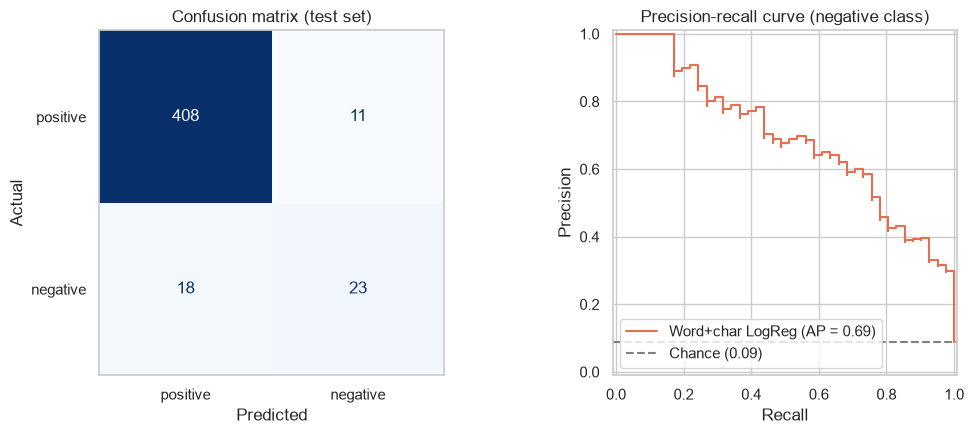

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["positive", "negative"], cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")
axes[0].grid(False)

PrecisionRecallDisplay.from_predictions(
    y_test, y_score, name="Word+char LogReg", curve_kwargs={"color": NEG_COLOR}, ax=axes[1],
)
axes[1].axhline(y_test.mean(), ls="--", color="grey", label=f"Chance ({y_test.mean():.2f})")
axes[1].set(title="Precision-recall curve (negative class)", xlabel="Recall", ylabel="Precision")
axes[1].legend(loc="lower left")

fig.tight_layout()
fig.savefig(IMAGES / "evaluation.png", dpi=150, bbox_inches="tight")

On the 460 held-out reviews, the scores match cross-validation, which is a good sign that model selection didn't overfit:

- **Recall 56%**: 23 of the 41 negative reviews are caught.
- **Precision 68%**: 23 of the 34 reviews flagged as negative really are.
- **11 false alarms** out of 419 positive reviews (2.6%).
- **PR-AUC 0.69**, against a chance level of 0.09.

These numbers use the default 0.5 probability threshold. The precision-recall curve shows how much room there is to move along the trade-off. For example, a support team triaging complaints would probably lower the threshold to catch more unhappy customers at the cost of more false alarms. Any such threshold should be chosen with cross-validated predictions on the training set, not by tuning against this test set.

## 6. What the model learned

The word-level TF-IDF features are interpretable: each has a logistic-regression coefficient, where large positive values push a review towards *negative* and large negative values towards *positive*.

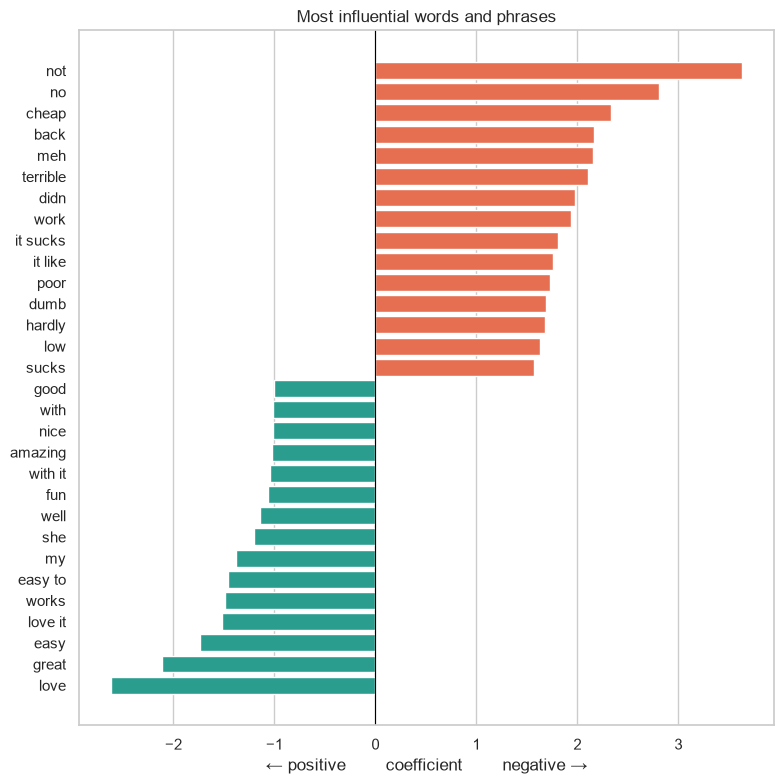

In [18]:
features = model.named_steps["features"]
coefs = model.named_steps["clf"].coef_[0]
names = features.get_feature_names_out()

word_mask = np.char.startswith(names.astype(str), "word__")
terms = pd.Series(coefs[word_mask], index=[n.removeprefix("word__") for n in names[word_mask]])

top_n = 15
top_terms = pd.concat([terms.nsmallest(top_n), terms.nlargest(top_n).iloc[::-1]])

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top_terms.index, top_terms.values, color=[POS_COLOR if v < 0 else NEG_COLOR for v in top_terms.values])
ax.axvline(0, color="black", lw=0.8)
ax.grid(axis="y", visible=False)
ax.set(title="Most influential words and phrases", xlabel="← positive        coefficient        negative →")
fig.tight_layout()
fig.savefig(IMAGES / "top_terms.png", dpi=150, bbox_inches="tight")

The learned weights make intuitive sense:

- **Negative signals** are explicit sentiment ("terrible", "poor", "sucks", "meh", "dumb"), negation ("not", "no", "didn't", "hardly"), product quality ("cheap", "low"), and *"back"* (as in sending it back). *"work"* is a negative signal while *"works"* is a positive one. Complaints are about things that don't work.
- **Positive signals** are dominated by "love", "great" and "easy (to use)". Personal words such as *"my"* and *"she"* (referring to Alexa) also lean positive, suggesting satisfied owners talk about the device as part of the household.

### Where it fails

Looking at the test-set mistakes, with the model's predicted probability of the review being negative:

In [19]:
errors = pd.DataFrame({
    "review": X_test,
    "rating": reviews.loc[X_test.index, "rating"],
    "p_negative": y_score.round(2),
    "actual": y_test.map({1: "negative", 0: "positive"}),
})
errors = errors[y_pred != y_test]

print("Missed negative reviews (false negatives):")
display(errors[errors["actual"] == "negative"].sort_values("p_negative").head(8))
print("Positive reviews flagged as negative (false positives):")
display(errors[errors["actual"] == "positive"].sort_values("p_negative", ascending=False).head(8))

Missed negative reviews (false negatives):


,review,rating,p_negative,actual
1464,I’m still unable to connect any devices although it says it has a built in hub. So bought a bridge to connect the de...,2,0.12,negative
2111,"When you think about it this really doesn’t do much. Play music, answer stupid questions, finally it was able to hoo...",2,0.12,negative
1154,The way the music sounds is poor quality,1,0.13,negative
377,Never could get it to work. A techie friend looked at it for me and said the adapter wasn't strong enough to power i...,1,0.19,negative
877,"I switched to google. The amazon helper is more for shopping, and google is the tasks assistant.",2,0.20,negative
1370,Alexa didn’t know answers to many questions we asked. For example we asked how many cups in a pound and she said a p...,1,0.20,negative
801,I wanted to use it as a clock in our bedroom. But the font is too small to see from any distance. And apparently y...,2,0.24,negative
2176,I am having real difficulty working with the Echo Dot. Alexi is not very smart. 9 out of 10 questions I have asked I...,1,0.24,negative


Positive reviews flagged as negative (false positives):


,review,rating,p_negative,actual
1694,Its ok... my home screen on my fire stick is not working on my television. So by that not working...Alexa will not r...,3,0.83,positive
606,I bought three of these and all three have worked flawlessly. If they weren't labeled as refurbished I wouldn't have...,5,0.76,positive
1507,"Connecting and sound are perfect! I only give 4 because the is no internal battery, if I disconnect to the power sou...",4,0.74,positive
509,"Worked as it should, still need to figure out how to link to other devices though, only set up Sonos which was prett...",5,0.68,positive
195,As described and received on time. Do not like automatic enrolment into music.,5,0.65,positive
551,I took a chance on a certified refurbished unit for $29. Looks brand new...no excuses or disappointments. 5 minute t...,5,0.58,positive
2017,"It won’t work as a blue tooth speaker with my tv,it connects but won’t work",3,0.58,positive
1453,I never had ALEXA before but the biggest reason I bought it was for YOUTUBE and apparently YOUTUBE stopped supportin...,4,0.56,positive


The errors fall into a few recognisable groups:

- **Understated complaints.** Missed negatives often describe a problem in neutral, factual language ("I switched to google…", "the font is too small to see from any distance") without any of the strongly negative words the model relies on.
- **Mixed reviews.** Many false positives are 3–5 star reviews that spend most of their words on a complaint ("I only give 4 because there is no internal battery…"). A bag-of-words model sees the complaint but can't weigh it against the overall verdict.
- **Negation and context.** "If they weren't labeled as refurbished I wouldn't have known" is praise built from negative-looking words.
- **Label boundary.** 3-star reviews count as *positive* by the dataset's definition, but several read as clearly dissatisfied ("Its ok… my home screen on my fire stick is not working"). Some of these "errors" are arguably label noise.

## 7. Conclusions

- Alexa reviews from this period are **overwhelmingly positive** (91%). Customer dissatisfaction is concentrated in particular devices, notably the plain Black/White variations and the Echo Spot/Show, while the fabric-finish Echos get the fewest complaints.
- **Negative reviews are longer** and focus on functionality: devices that don't work, connect or understand.
- A simple, fast and interpretable **TF-IDF + logistic regression** model flags negative reviews with **PR-AUC 0.69** (chance 0.09) and **F1 0.61** on unseen reviews, catching over half of unhappy customers while keeping false alarms under 3%.
- **Data hygiene mattered as much as model choice.** Deduplication removed a quarter of the dataset and prevented a ~8-point overestimate of F1. Choosing metrics suited to the imbalance prevented a "91% accurate" model that does nothing.

### Possible next steps

- **Tune the decision threshold** on cross-validated predictions for a specific use case (e.g. high-recall complaint triage).
- **Treat 3-star reviews as a separate "neutral" class**, since many of them read as complaints.
- **Try a pre-trained transformer** (e.g. a fine-tuned DistilBERT), which should handle negation, mixed sentiment and understated complaints better than bag-of-words features.
- **Collect more negative examples.** With only ~200 distinct negative reviews, the model has little to learn from, which is the main limit on recall.